In [34]:
import pandas as pd
import numpy as np

df = pd.read_csv("titanic.csv")

print(df.head())
print("Dataset shape:", df.shape)
print(df.info())
print(df.isnull().sum())

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN        S  
Da

In [35]:
X = df.drop(columns=[
    "Survived",
    "PassengerId",
    "Name",
    "Ticket",
    "Cabin"
])

y = df["Survived"]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (891, 7)
Target: (891,)


In [36]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (712, 7)
Testing data: (179, 7)


In [37]:
print(X_train.isnull().sum())

Pclass        0
Sex           0
Age         137
SibSp         0
Parch         0
Fare          0
Embarked      2
dtype: int64


In [38]:
num_cols = X_train.select_dtypes(
    include=["number"]
).columns

cat_cols = X_train.select_dtypes(
    exclude=["number"]
).columns

print("Numerical columns:", list(num_cols))
print("Categorical columns:", list(cat_cols))

Numerical columns: ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
Categorical columns: ['Sex', 'Embarked']


In [39]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Numerical pipeline
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical pipeline
cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both pipelines
preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_cols),
    ("cat", cat_pipeline, cat_cols)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [40]:
from sklearn.ensemble import RandomForestClassifier

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [41]:
from sklearn.metrics import accuracy_score, classification_report

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.8156424581005587
              precision    recall  f1-score   support

           0       0.82      0.89      0.86       110
           1       0.80      0.70      0.74        69

    accuracy                           0.82       179
   macro avg       0.81      0.79      0.80       179
weighted avg       0.81      0.82      0.81       179



           Feature  Importance
4        num__Fare    0.258759
1         num__Age    0.243951
6    cat__Sex_male    0.158605
5  cat__Sex_female    0.131465
0      num__Pclass    0.085362
2       num__SibSp    0.046857
3       num__Parch    0.040157
9  cat__Embarked_S    0.014058
7  cat__Embarked_C    0.012751
8  cat__Embarked_Q    0.008034


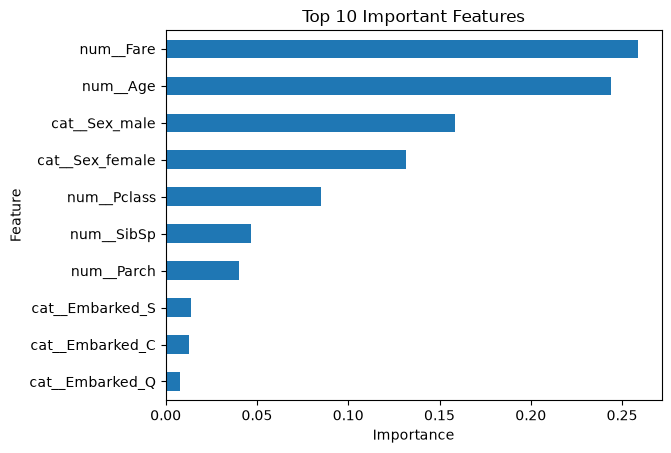

In [42]:
import matplotlib.pyplot as plt

feature_names = model.named_steps[
    "preprocessor"
].get_feature_names_out()

importances = model.named_steps[
    "classifier"
].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(importance_df.head(10))

importance_df.head(10).plot(
    x="Feature",
    y="Importance",
    kind="barh",
    legend=False
)

plt.title("Top 10 Important Features")
plt.xlabel("Importance")
plt.gca().invert_yaxis()
plt.show()

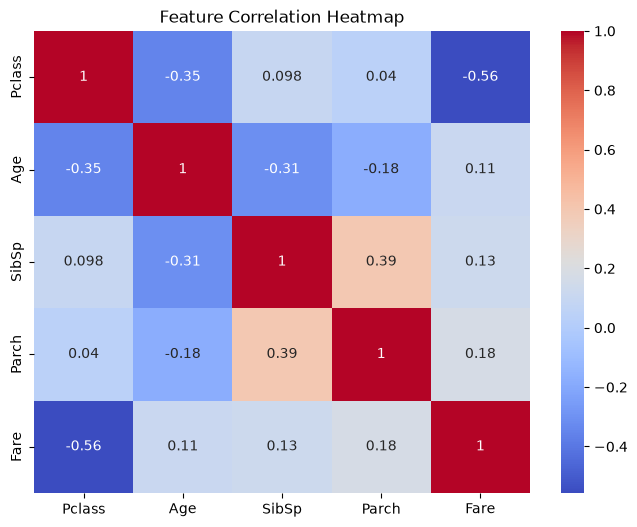

In [43]:
import seaborn as sns

correlation = X_train.select_dtypes(
    include=["number"]
).corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm"
)

plt.title("Feature Correlation Heatmap")
plt.show()

## Conclusion

In this project, I developed a machine learning preprocessing pipeline using the Titanic passenger survival dataset.

I performed missing-value imputation, numerical feature scaling, categorical feature encoding, and correlation analysis using Scikit-Learn.

I used a train-test split to prevent data leakage and trained a Random Forest classifier to predict passenger survival. I evaluated the model using accuracy, precision, recall, and F1-score.

Finally, I analyzed feature importance to identify the features that contributed most to the model's predictions.

This project helped me understand how to build a reusable and reliable machine learning preprocessing pipeline.